# 04 — Experiment log explorer (read-only)

Browse eval records as a table: which runs exist, how their scores compare, and how a task moved over time.

| `LOG` setting | Reads |
| --- | --- |
| `"notebook"` (default) | `data/runtime/notebooks/experiment_log.jsonl`, written by notebook 03 |
| `"reports"` | `reports/experiment_log.jsonl`, the sandbox's real log (gitignored, local to this machine) |
| any other string | a JSONL path, absolute or relative to the repo root |

This notebook **only reads**. It writes nothing and needs no profile or model.

**Read with care:** compare runs only when they share a `task` **and** a `dataset_fingerprint`. Mock rows (`mock == True`) only check plumbing, so they are hidden from the charts unless `INCLUDE_MOCK = True`.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

# Works with or without `pip install -e .`: fall back to the checkout's src/ when needed.
try:
    import mailroom_sandbox  # noqa: F401
except ModuleNotFoundError:
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "src" / "mailroom_sandbox").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import mailroom_sandbox  # noqa: F401

import os

from mailroom_sandbox.notebook import bootstrap

ctx = bootstrap(create_dotenv=False, activate_profile=False)

LOG = os.environ.get("SANDBOX_NOTEBOOK_LOG_VIEW", "notebook")  # "notebook" | "reports" | a path
INCLUDE_MOCK = True  # set False to hide mock rows from the tables and charts

if LOG == "notebook":
    log_path = ctx.experiment_log
elif LOG == "reports":
    log_path = ctx.root / "reports" / "experiment_log.jsonl"
else:
    log_path = Path(LOG) if Path(LOG).is_absolute() else ctx.root / LOG
print("reading", log_path)

reading /demo/runtime/log/experiment_log.jsonl


In [2]:
try:
    import pandas as pd
except ImportError as exc:  # pragma: no cover - guidance for a bare [dev] install
    raise ImportError('pandas is missing: pip install -e ".[dev,notebooks]"') from exc

pd.set_option("display.max_colwidth", 80)

from mailroom_sandbox.datasets import load_jsonl

records = load_jsonl(log_path)
print(f"{len(records)} records loaded from {log_path}")
if not records:
    print("no records yet; run notebook 03 (or point LOG at another log) and rerun this cell")


3 records loaded from /demo/runtime/log/experiment_log.jsonl


## 1. Flatten records into a table

Each record carries identity fields (task, profile, provider, model, prompt version, dataset fingerprint, git snapshot) and a nested `scores` dict. The scores that sandbox tasks share are pulled into columns.

In [3]:
SCORE_KEYS = ["exact_match", "f1_macro", "stage_correct", "extraction_overall", "routing_accuracy",
              "schema_valid_rate", "parse_error_rate"]


def flatten(record: dict) -> dict:
    scores = record.get("scores") or {}
    git = record.get("git") or {}
    row = {
        "timestamp": record.get("timestamp"),
        "experiment": record.get("experiment_name"),
        "task": record.get("task"),
        "profile": record.get("profile"),
        "provider": record.get("provider"),
        "model": record.get("model"),
        "prompt": record.get("prompt_version"),
        "mock": bool(record.get("mock")),
        "n": record.get("n"),
        "fingerprint": record.get("dataset_fingerprint"),
        "git": (git.get("sha") or git.get("commit") or "")[:10] if isinstance(git, dict) else "",
    }
    row.update({k: scores.get(k) for k in SCORE_KEYS})
    return row


runs = pd.DataFrame([flatten(r) for r in records])
if not runs.empty:
    runs["timestamp"] = pd.to_datetime(runs["timestamp"], errors="coerce", utc=True)
    runs = runs.sort_values("timestamp")
    if not INCLUDE_MOCK:
        runs = runs[~runs["mock"]]
    score_cols = [c for c in SCORE_KEYS if runs[c].notna().any()]
    print(f"{len(runs)} records, {runs['task'].nunique()} tasks, {runs['mock'].sum()} mock")
    display(runs.tail(15))

3 records, 2 tasks, 3 mock


,timestamp,experiment,task,profile,provider,model,prompt,mock,n,fingerprint,git,exact_match,f1_macro,stage_correct,extraction_overall,routing_accuracy,schema_valid_rate,parse_error_rate
0,2026-11-27 00:06:32.943406+00:00,notebook_sorter_fixtures,sorter,ollama,ollama,qwen3:8b,sorter_condensed_v5,True,11,ac483bde2aab,966822bc,1.0,1.0,NaN,NaN,NaN,NaN,NaN
1,2026-11-27 00:06:33.075313+00:00,notebook_sorter_balanced,sorter,ollama,ollama,qwen3:8b,sorter_condensed_v5,True,6,8671bb8d5133,966822bc,1.0,1.0,NaN,NaN,NaN,NaN,NaN
2,2026-11-27 00:06:34.439759+00:00,notebook_offline_pipeline,pipeline,ollama,ollama,NaN,mailroom-default,True,4,e506bd4057dc,966822bc,1.0,1.0,1.0,0.5,1.0,0.5,0.0


## 2. Summary by run identity

Groups by task, profile, model, mock flag and dataset fingerprint. Rows in the same group are repeat runs of the same setup.

In [4]:
if runs.empty:
    print("nothing to summarize")
else:
    identity = ["task", "profile", "provider", "model", "prompt", "mock", "fingerprint"]
    summary = (
        runs.fillna({"model": "(default)", "profile": "?", "provider": "?", "prompt": "(default)"})
        .groupby(identity, dropna=False)
        .agg(runs=("n", "size"), docs=("n", "sum"), last=("timestamp", "max"),
             **{f"mean_{c}": (c, "mean") for c in score_cols})
        .round({f"mean_{c}": 3 for c in score_cols})
        .sort_values("last", ascending=False)
    )
    display(summary)

runs  \
task     profile provider model     prompt              mock fingerprint          
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc     1   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133     1   
                                                             ac483bde2aab     1   

                                                                           docs  \
task     profile provider model     prompt              mock fingerprint          
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc     4   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133     6   
                                                             ac483bde2aab    11   

                                                                                                      last  \
task     profile provider model     prompt              mock fingerprint                                     
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc 2026-11-27 00:06:34.439759+00:00   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133 2026-11-27 00:06:33.075313+00:00   
                                                             ac483bde2aab 2026-11-27 00:06:32.943406+00:00   

                                                                           mean_exact_match  \
task     profile provider model     prompt              mock fingerprint                      
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc               1.0   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133               1.0   
                                                             ac483bde2aab               1.0   

                                                                           mean_f1_macro  \
task     profile provider model     prompt              mock fingerprint                   
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc            1.0   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133            1.0   
                                                             ac483bde2aab            1.0   

                                                                           mean_stage_correct  \
task     profile provider model     prompt              mock fingerprint                        
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc                 1.0   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133                 NaN   
                                                             ac483bde2aab                 NaN   

                                                                           mean_extraction_overall  \
task     profile provider model     prompt              mock fingerprint                             
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc                      0.5   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133                      NaN   
                                                             ac483bde2aab                      NaN   

                                                                           mean_routing_accuracy  \
task     profile provider model     prompt              mock fingerprint                           
pipeline ollama  ollama   (default) mailroom-default    True e506bd4057dc                    1.0   
sorter   ollama  ollama   qwen3:8b  sorter_condensed_v5 True 8671bb8d5133                    NaN   
                                                             ac483bde2aab                    NaN   

                                                                           mean_schema_valid_rate  \
task     profile provider model     prompt              mock fingerprint                            
pipeline ollama  ollama   (default) mailroom-default   

## 3. What the log holds

Runs per task, real versus mock. Mock runs score 100% by construction, so only the coloured part of each bar measures quality. Colours follow the house roles in `mailroom_sandbox.figure_style` (decision model blue, LLM sorter orange, other systems aqua).

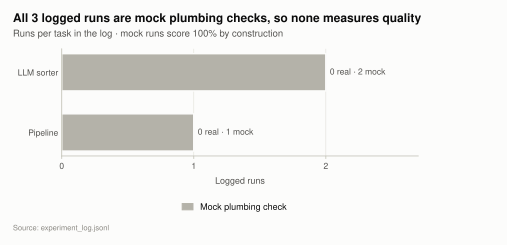

,task,label,real,mock
0,pipeline,Pipeline,0,1
1,sorter,LLM sorter,0,2


In [5]:
from IPython.display import SVG

from mailroom_sandbox import log_figures as lf

rows = [lf.flatten_record(r) for r in records]
plot_rows = rows if INCLUDE_MOCK else [r for r in rows if not r["mock"]]
svg, data = lf.inventory_svg(rows, source=log_path.name)
display(SVG(svg))
display(pd.DataFrame(data))

## 4. Pick a comparable cohort

Scores compare only within one task **and** one dataset fingerprint. Cohorts with the most real runs come first; set `COHORT` to another row index to change the next two figures.

In [6]:
cohort_table = pd.DataFrame(lf.cohorts(plot_rows))
display(cohort_table.head(15))

COHORT = 0  # row index in the table above
cohort = cohort_table.iloc[COHORT] if not cohort_table.empty else None
if cohort is not None:
    print(f"cohort: {lf.task_label(cohort['task'])} · dataset {cohort['fingerprint']} · "
          f"{cohort['real_runs']} real of {cohort['runs']} runs")

,task,fingerprint,runs,real_runs,documents,setups
0,pipeline,e506bd4057dc,1,0,4,1
1,sorter,8671bb8d5133,1,0,6,1
2,sorter,ac483bde2aab,1,0,11,1


cohort: Pipeline · dataset e506bd4057dc · 0 real of 1 runs


## 5. Which setup leads in this cohort

Exact match pooled over every run of each model and prompt setup, with a 95% Wilson interval. Overlapping intervals mean the data cannot yet rank the setups. Hollow markers are mock runs.

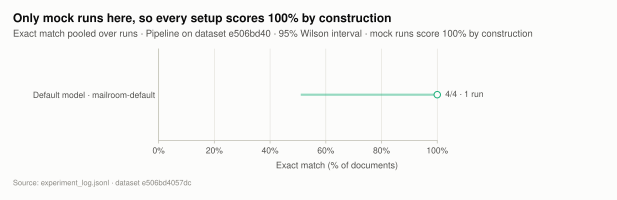

,setup,model,prompt,runs,correct,documents,rate,low,high
0,Default model · mailroom-default,None,mailroom-default,1,4,4,1.0,0.51,1.0


In [7]:
if cohort is None:
    print("no scored runs to compare")
else:
    svg, data = lf.setups_svg(plot_rows, cohort["task"], cohort["fingerprint"], source=log_path.name)
    display(SVG(svg))
    display(pd.DataFrame(data).round(3))

## 6. How the cohort moved run by run

Each run's exact match with its 95% Wilson interval, oldest first. With a handful of documents per run the intervals are wide, so read a change only where they separate.

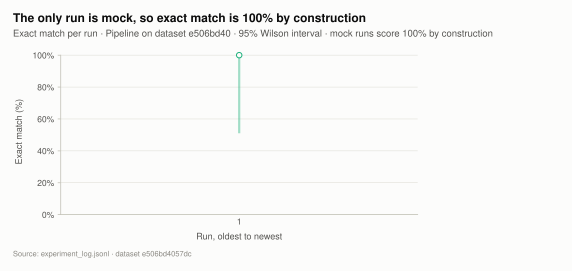

,run,experiment,timestamp,setup,correct,documents,rate,low,high
0,1,notebook_offline_pipeline,2026-11-27T00:06:34.439759+00:00,Default model · mailroom-default,4,4,1.0,0.51,1.0


In [8]:
if cohort is None:
    print("no scored runs to plot")
else:
    svg, data = lf.trend_svg(plot_rows, cohort["task"], cohort["fingerprint"], source=log_path.name)
    display(SVG(svg))
    display(pd.DataFrame(data).round(3))

## 7. Inspect one record

Set `EXPERIMENT` to an experiment name from the table above to see its latest record in full, including the per-class scores and the git snapshot.

In [9]:
EXPERIMENT = runs["experiment"].iloc[-1] if not runs.empty else None

matches = [r for r in records if r.get("experiment_name") == EXPERIMENT]
if matches:
    print(json.dumps(matches[-1], indent=2, default=str)[:4000])
else:
    print("no matching record")

{
  "timestamp": "2026-11-27T00:06:34.439759+00:00",
  "sandbox": true,
  "git": {
    "commit": "966822bc",
    "dirty": true
  },
  "experiment_name": "notebook_offline_pipeline",
  "task": "pipeline",
  "profile": "ollama",
  "provider": "ollama",
  "model": null,
  "prompt_version": "mailroom-default",
  "mock": true,
  "dataset_fingerprint": "e506bd4057dc",
  "n": 4,
  "scores": {
    "exact_match": 1.0,
    "accuracy": 1.0,
    "exact_match_ci": {
      "lo": 1.0,
      "hi": 1.0,
      "half": 0.0,
      "n": 4,
      "seed": 42,
      "n_boot": 2000,
      "method": "percentile-bootstrap"
    },
    "n": 4,
    "task": {
      "task": "docclass",
      "kind": "docclass",
      "doc_type_accuracy": 1.0,
      "accuracy": 1.0,
      "doc_type_accuracy_ci": {
        "lo": 1.0,
        "hi": 1.0,
        "half": 0.0,
        "n": 4,
        "seed": 42,
        "n_boot": 2000,
        "method": "percentile-bootstrap"
      },
      "per_class": {
        "compliance_filing": {
   